# Data preparation

This notebook turns the raw Sensor Logger exports into labeled windows of 255 readings (5.1 seconds).
For each activity it loads the accelerometer and gyroscope files, merges them into one
table, trims the settling period at the start, and cuts the rest into fixed-length windows.


In [1]:
from pathlib import Path

import pandas as pd

RAW_DIR = Path("../data/raw")
ACTIVITIES = ["Standing", "Walking", "Jumping", "Still"]

SAMPLING_RATE_HZ = 50
WINDOW_SECONDS = 5.1  # the span from first to last timestamp is then at least 5 s
WINDOW_ROWS = round(SAMPLING_RATE_HZ * WINDOW_SECONDS)  # 255 readings per window
TRIM_SECONDS = 5  # settling motion at the start of each recording

AXES = ["x", "y", "z"]
COLUMNS = ["time_s"] + [f"acc_{a}" for a in AXES] + [f"gyro_{a}" for a in AXES]

## Load and merge the two sensors

The accelerometer and gyroscope files use the same column names, so the columns are
renamed with a sensor prefix. Columns are always selected by name, because the raw files
list them in the order z, y, x. The two files must have the same rows at the same times,
which is checked before they are merged.

In [2]:
def load_recording(activity, raw_dir=RAW_DIR):
    """Return one table with time_s and the six sensor columns for an activity."""
    acc = pd.read_csv(raw_dir / activity / "Accelerometer.csv")
    gyro = pd.read_csv(raw_dir / activity / "Gyroscope.csv")

    if len(acc) != len(gyro) or not (acc["time"].values == gyro["time"].values).all():
        raise ValueError(f"{activity}: accelerometer and gyroscope timestamps do not match")

    table = pd.DataFrame({"time_s": acc["seconds_elapsed"]})
    for axis in AXES:
        table[f"acc_{axis}"] = acc[axis]
    for axis in AXES:
        table[f"gyro_{axis}"] = gyro[axis]
    return table[COLUMNS]


recordings = {activity: load_recording(activity) for activity in ACTIVITIES}
for activity, table in recordings.items():
    print(f"{activity:9s} rows={len(table)}  duration={table['time_s'].iloc[-1]:.1f}s")

Standing  rows=6136  duration=123.0s
Walking   rows=6190  duration=124.1s
Jumping   rows=6135  duration=123.0s
Still     rows=6167  duration=123.7s


**What the output shows.** The four recordings have 6,135 to 6,190 readings and last about 123 to 124 s (the last timestamp, which starts about 0.13 s after zero). In each recording the accelerometer and gyroscope have the same rows at the same times, otherwise the loading function would have stopped with an error.

### Sampling interval

The time between consecutive readings in each recording, measured from the timestamps.

In [3]:
import numpy as np

rows = []
for activity, table in recordings.items():
    gaps_ms = np.diff(table["time_s"].to_numpy()) * 1000
    rows.append({
        "activity": activity,
        "rows": len(table),
        "duration_s": table["time_s"].iloc[-1] - table["time_s"].iloc[0],
        "interval_mean_ms": gaps_ms.mean(),
        "interval_min_ms": gaps_ms.min(),
        "interval_max_ms": gaps_ms.max(),
        "rate_hz": 1000 / gaps_ms.mean(),
    })
pd.DataFrame(rows).set_index("activity").round(2)

,rows,duration_s,interval_mean_ms,interval_min_ms,interval_max_ms,rate_hz
activity,,,,,,
Standing,6136,122.90,20.03,20.03,20.03,49.92
Walking,6190,123.99,20.03,20.03,20.04,49.91
Jumping,6135,122.90,20.04,20.03,20.04,49.91
Still,6167,123.53,20.03,20.03,20.04,49.92


**What the output shows.** The time between two readings is 20.03 to 20.04 ms in every recording, a rate of 49.91 to 49.92 Hz against the nominal 50 Hz. The smallest and largest gap differ by about 0.01 ms, so the readings are evenly spaced and no sample was dropped. Only one phone and one app were used, so there are no different sampling rates to harmonize and no resampling is applied. The window length is therefore set as a number of readings (255).

### Start of each recording

The size of the accelerometer movement (square root of the summed variances of the three axes) in the first 5 s, the next 5 s and the rest of each recording.

In [4]:
def movement_size(table):
    """Square root of the summed variances of the three accelerometer axes."""
    return float(np.sqrt(sum(table[f"acc_{a}"].var() for a in AXES)))


periods = {"first 5 s": (0, 5), "5 to 10 s": (5, 10), "10 s to end": (10, np.inf)}
start_check = {
    activity: {
        name: movement_size(table[(table["time_s"] >= lo) & (table["time_s"] < hi)])
        for name, (lo, hi) in periods.items()
    }
    for activity, table in recordings.items()
}
pd.DataFrame(start_check).T.round(3)

,first 5 s,5 to 10 s,10 s to end
Standing,0.781,0.154,0.219
Walking,1.130,1.108,1.267
Jumping,4.887,6.276,8.497
Still,1.577,0.013,0.014


**What the output shows.** The table gives the size of the accelerometer movement in three periods of each recording. For Still the first 5 s measure 1.577 against 0.013 afterwards, and for Standing 0.781 against 0.154, so the phone is being handled at the start and that stretch is not the activity. For Walking (1.130 against 1.108) and Jumping (4.887 against 6.276) the first 5 s do not stand out. The same 5 s trim is applied to all four activities as one common rule, which this table justifies only for Still and Standing. The Jumping value keeps growing during the recording (8.497 from 10 s to the end), so jumping is stronger in the later part of the recording.

## Trim and cut into windows

The first 5 seconds are removed from every recording. The table above shows a clear start effect
for Still and Standing and none for Walking and Jumping, so one common rule is used. The rest is cut into consecutive windows of 255 rows (5.1 seconds at
50 Hz, so each file spans more than 5 s from its first to its last timestamp). A final stretch shorter than a full window is dropped, so every window has the same
length and gives comparable features.

In [5]:
def trim_start(table, seconds=TRIM_SECONDS):
    """Drop the readings recorded in the first `seconds` of the recording."""
    return table[table["time_s"] >= seconds].reset_index(drop=True)


def split_into_windows(table, window_rows=WINDOW_ROWS):
    """Cut a table into consecutive, non-overlapping windows of equal length."""
    n_windows = len(table) // window_rows
    return [
        table.iloc[i * window_rows:(i + 1) * window_rows].reset_index(drop=True)
        for i in range(n_windows)
    ]


windows = {
    activity: split_into_windows(trim_start(table))
    for activity, table in recordings.items()
}

summary = pd.DataFrame({
    "windows": {a: len(w) for a, w in windows.items()},
    "seconds_used": {a: len(w) * WINDOW_SECONDS for a, w in windows.items()},
})
summary.loc["total"] = summary.sum()
summary

,windows,seconds_used
Standing,23.0,117.3
Walking,23.0,117.3
Jumping,23.0,117.3
Still,23.0,117.3
total,92.0,469.2


**What the output shows.** Each activity gives 23 full windows, which is 117.3 s of signal per activity and 92 windows in total. The end of each recording after the last full window is under 2 s long and is dropped, so that every window has the same length.

### Window length and frequency resolution

How long a window of 250 or 255 readings is, measured from the first to the last timestamp.

In [6]:
for rows_per_window in (250, WINDOW_ROWS):
    spans = [w["time_s"].iloc[rows_per_window - 1] - w["time_s"].iloc[0]
             for activity_windows in windows.values() for w in activity_windows]
    print(f"{rows_per_window} readings: span from first to last timestamp "
          f"{min(spans):.3f} to {max(spans):.3f} s")

rate_hz = 1 / np.diff(recordings["Walking"]["time_s"]).mean()
print(f"Spacing of the frequencies in the FFT of one window (rate / readings): {rate_hz / WINDOW_ROWS:.3f} Hz")
print(f"Highest frequency a window can show (half the measured rate): "
      f"{rate_hz / 2:.2f} Hz")

250 readings: span from first to last timestamp 4.988 to 4.989 s
255 readings: span from first to last timestamp 5.088 to 5.089 s
Spacing of the frequencies in the FFT of one window (rate / readings): 0.196 Hz
Highest frequency a window can show (half the measured rate): 24.96 Hz


**What the output shows.** A window of 250 readings spans only 4.988 s from first to last timestamp, which is below the 5 s minimum of the assignment. A window of 255 readings spans 5.088 s, so 255 was chosen. This choice was made to meet the 5 s minimum; other window lengths were not compared. The FFT of one window of 255 readings has a frequency spacing of 49.92 / 255 = 0.196 Hz, up to 24.96 Hz, the highest frequency the measured rate can show.

## Checks

Every window must have exactly 255 rows, exactly 6 sensor columns plus time, and no empty values.
Consecutive windows of one activity must follow each other without a gap or overlap.

In [7]:
for activity, activity_windows in windows.items():
    for number, window in enumerate(activity_windows, start=1):
        assert len(window) == WINDOW_ROWS, (activity, number, len(window))
        assert list(window.columns) == COLUMNS
        assert not window.isna().any().any()
    for before, after in zip(activity_windows, activity_windows[1:]):
        step = after["time_s"].iloc[0] - before["time_s"].iloc[-1]
        assert abs(step - 1 / SAMPLING_RATE_HZ) < 1e-4, (activity, step)

print("All windows pass the checks.")

All windows pass the checks.


**What the output shows.** Every window passed: 255 rows, the expected columns, no empty values, and no gap or overlap between consecutive windows (a failed check would have stopped the notebook with an error). The data was not filtered, resampled, interpolated or cleaned of outliers. The only changes are the 5 s trim, the dropped end of each recording and these checks.

## Save the windows

Each window is saved as its own CSV file, in a folder named after the activity, for example
`data/processed/walking/walking_07.csv`. The files are numbered in time order, and `time_s`
inside each file gives the position in the original recording. An `activity` column holds
the label.

In [8]:
PROCESSED_DIR = Path("../data/processed")


def save_windows(activity, activity_windows, out_dir=PROCESSED_DIR):
    """Write each window to <out_dir>/<activity>/<activity>_NN.csv with an activity label."""
    folder = out_dir / activity.lower()
    folder.mkdir(parents=True, exist_ok=True)
    for number, window in enumerate(activity_windows, start=1):
        labeled = window.assign(activity=activity)
        labeled.to_csv(folder / f"{activity.lower()}_{number:02d}.csv", index=False)


for activity, activity_windows in windows.items():
    save_windows(activity, activity_windows)

print(sum(len(w) for w in windows.values()), "files written to", PROCESSED_DIR)

92 files written to ..\data\processed


**What the output shows.** 92 files were written, 23 in each of the four activity folders. The files are numbered in time order and `time_s` keeps the position in the original recording. The windows do not overlap, so no reading appears in two files.

## Sample windows

One 5.1-second window per activity, taken from the middle of each recording. The top row
shows the accelerometer and the bottom row the gyroscope. Each row shares one vertical
scale across the four activities, so differences in how strongly the signal moves can be
compared directly.

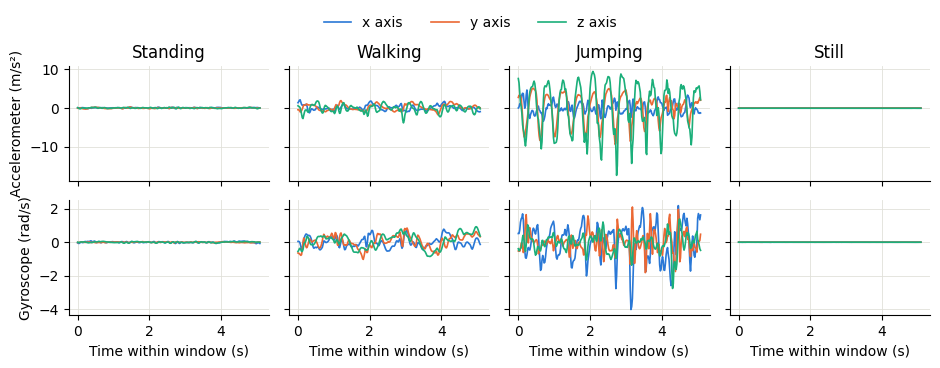

In [9]:
import matplotlib.pyplot as plt

AXIS_COLORS = {"x": "#2a78d6", "y": "#eb6834", "z": "#1baf7a"}
SAMPLE_WINDOW = 12  # a window from the middle of each recording (1-based)
FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(exist_ok=True)

fig, axes = plt.subplots(2, len(ACTIVITIES), figsize=(9.5, 3.7), sharex=True, sharey="row")
for col, activity in enumerate(ACTIVITIES):
    window = windows[activity][SAMPLE_WINDOW - 1]
    t = window["time_s"] - window["time_s"].iloc[0]
    for row, sensor in enumerate(["acc", "gyro"]):
        ax = axes[row, col]
        for axis in AXES:
            ax.plot(t, window[f"{sensor}_{axis}"], color=AXIS_COLORS[axis], linewidth=1.2, label=f"{axis} axis")
        ax.grid(color="#e1e0d9", linewidth=0.6)
        ax.set_axisbelow(True)
        for side in ["top", "right"]:
            ax.spines[side].set_visible(False)
    axes[0, col].set_title(activity)
    axes[1, col].set_xlabel("Time within window (s)")

axes[0, 0].set_ylabel("Accelerometer (m/s²)")
axes[1, 0].set_ylabel("Gyroscope (rad/s)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(FIGURES_DIR / "sample_windows.png", dpi=200, bbox_inches="tight")
plt.show()

**What the figure shows.** Window 12 of each activity (from the middle of the recording), with one vertical scale per row so the four activities can be compared. Still is flat on both sensors, Standing stays close to zero, Walking stays between about -4 and 2 on the accelerometer, and Jumping swings from about -17 to 9. The accelerometer is in m/s² and the gyroscope in rad/s, as stated in the Sensor Logger documentation. This is one example window per activity: Jumping gets stronger during its recording (see the table on the start of each recording), so a single window does not show its whole range.